Config

In [1]:
# Libraries
import pandas as pd
pd.set_option("display.max_columns", None)
import numpy as np
import lightgbm as lgb
from catboost import CatBoostClassifier

In [2]:
DATA_PATH = "data/UCI_Credit_Card.csv"

In [3]:
SEED = 42
FOLD = 3

In [4]:
df_raw = pd.read_csv(DATA_PATH)
df_raw.shape

(30000, 25)

In [5]:
PAY = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']
BILL = [f'BILL_AMT{i}' for i in range(1, 7)]
PAID = [f'PAY_AMT{i}' for i in range(1, 7)]
PROFILE = ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE']
RAW = PROFILE + PAY + BILL + PAID
TARGET = 'default.payment.next.month'

Trong dataset, có 35 dòng có `ID` khác nhau nhưng các biến đặc trưng và nhãn giống hệt nhau, ta drop các dòng này

In [6]:
df_clean = df_raw.drop_duplicates(subset=RAW + [TARGET], keep="first").copy()
df_clean

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,1,3,1,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,1,3,2,43,-1,-1,-1,-1,0,0,1683.0,1828.0,3502.0,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,1,2,2,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,1,3,1,41,1,-1,0,0,0,-1,-1645.0,78379.0,76304.0,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


**Cách chia và lựa chọn mô hình:**
- Chia xấp xỉ 60/20/20 bằng StratifiedGroupKFold: 1/5 cho test, rồi 1/4 phần còn lại cho validation. Tỷ lệ không chính xác tuyệt đối do kích thước nhóm.
- Nhóm các predictor trùng hoàn toàn (kể cả khác nhãn) và lịch sử khớp dịch một tháng theo heuristic sẵn có. Đây là liên kết cấu trúc, chưa xác nhận cùng khách hàng.
- Train: CV 3 fold theo nhóm để chọn bộ đặc trưng, mô hình và một trong hai cấu hình định trước bằng mean AP; preprocessing chỉ fit trong fold train. Refit ứng viên thắng trên toàn bộ train.
- Validation: chỉ chọn ngưỡng tối đa F1 của lớp default. F1 cân bằng precision/recall; không bảo đảm đạt một mức recall nghiệp vụ cụ thể.
- Test: báo cáo sau khi khóa mô hình và ngưỡng, không chọn lại dựa trên điểm test.

**Giới hạn:** Dữ liệu và các tập test trước đây đã được xem trong nhiều thực nghiệm. Chia lại theo nhóm giảm chồng lấp cấu trúc nhưng không tạo ra dữ liệu mới chưa từng quan sát. Kết quả là đánh giá nội bộ; cần dữ liệu ngoài mẫu để xác nhận tổng quát hóa. Cấu hình ứng viên được tham khảo từ các nghiên cứu trước, không phải tìm kiếm toàn bộ không gian siêu tham số.

In [7]:
from sklearn.model_selection import StratifiedGroupKFold

def history_groups(X):
    """Conservatively group exact predictors and strong five-month shift matches in train."""
    frame = X[RAW].reset_index(drop=True)
    parent = np.arange(len(frame))

    def root(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    def union(a, b):
        parent[root(a)] = root(b)

    exact = frame.groupby(RAW, sort=False, dropna=False).ngroup()
    for indices in exact.groupby(exact).indices.values():
        for i in indices[1:]:
            union(int(indices[0]), int(i))

    left_cols = PROFILE + PAY[:5] + BILL[:5] + PAID[:5]
    right_cols = PROFILE + PAY[1:] + BILL[1:] + PAID[1:]
    keys = [f'k{i}' for i in range(len(left_cols))]
    left = frame[left_cols].set_axis(keys, axis=1).assign(a=frame.index)
    right = frame[right_cols].set_axis(keys, axis=1).assign(b=frame.index)
    pairs = left.merge(right, on=keys)[['a', 'b']]
    pairs = pairs.loc[pairs.a.ne(pairs.b)].copy()
    overlap = [frame.loc[pairs.a, cols[:5]].to_numpy() for cols in [PAY, BILL, PAID]]
    nonzero = (overlap[1] != 0).any(axis=1) | (overlap[2] != 0).any(axis=1)
    varying = np.logical_or.reduce([np.ptp(values, axis=1) > 0 for values in overlap])
    pairs = pairs.loc[nonzero & varying]
    for a, b in pairs.itertuples(index=False, name=None):
        union(a, b)
    groups = np.array([root(i) for i in range(len(frame))])
    for a, b in pairs.itertuples(index=False, name=None):
        assert groups[a] == groups[b]
    assert pd.DataFrame({'exact': exact, 'g': groups}).groupby('exact').g.nunique().max() == 1
    return groups, len(pairs)

X = df_clean[RAW].copy()
y = df_clean[TARGET]
# Grouping uses predictors only, never the target.
group_values, shift_pair_count = history_groups(X)
groups = pd.Series(group_values, index=X.index, name='history_group')
print(f'{groups.nunique():,} groups; {shift_pair_count:,} candidate shifted-history pairs')

28,892 groups; 1,052 candidate shifted-history pairs


In [8]:
# About 60/20/20, with no structural group crossing split boundaries.
outer_split = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
model_idx, test_idx = next(outer_split.split(X, y, groups))
X_model, X_test = X.iloc[model_idx].copy(), X.iloc[test_idx].copy()
y_model, y_test = y.iloc[model_idx].copy(), y.iloc[test_idx].copy()
groups_model = groups.loc[X_model.index]

inner_split = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
train_idx, val_idx = next(inner_split.split(X_model, y_model, groups_model))
X_train, X_val = X_model.iloc[train_idx].copy(), X_model.iloc[val_idx].copy()
y_train, y_val = y_model.iloc[train_idx].copy(), y_model.iloc[val_idx].copy()
groups_train = groups.loc[X_train.index]

for left, right in [(X_train, X_val), (X_train, X_test), (X_val, X_test)]:
    assert set(groups.loc[left.index]).isdisjoint(groups.loc[right.index])
assert len(X_train) + len(X_val) + len(X_test) == len(X)

cv = StratifiedGroupKFold(n_splits=FOLD, random_state=SEED, shuffle=True)
df_train = X_train.join(y_train)

In [9]:
split_summary = pd.DataFrame([
    {"split": name, "rows": len(labels), "share": len(labels) / len(y),
     "default_rate": labels.mean()}
    for name, labels in [("train", y_train), ("validation", y_val), ("test", y_test)]
])

split_summary

,split,rows,share,default_rate
0,train,17977,0.599933,0.221283
1,validation,5994,0.200033,0.221221
2,test,5994,0.200033,0.221221


# EDA

Chỉ phân tích tập train; validation và test được giữ riêng để đánh giá.

In [10]:
df_train.sort_index()

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29992,10000.0,1,3,1,43,0,0,0,-2,-2,-2,8802.0,10400.0,0.0,0.0,0.0,0.0,2000.0,0.0,0.0,0.0,0.0,0.0,0
29994,80000.0,1,2,2,34,2,2,2,2,2,2,72557.0,77708.0,79384.0,77519.0,82607.0,81158.0,7000.0,3500.0,0.0,7000.0,0.0,4000.0,1
29995,220000.0,1,3,1,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29997,30000.0,1,2,2,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1


In [11]:
df_train[df_train.duplicated()]

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month


In [12]:
df_train.isnull().sum()

LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default.payment.next.month    0
dtype: int64

In [13]:
# Matplotlib
import matplotlib.pyplot as plt

plt.rcParams['figure.figsize'] = (10, 4)

**Phân phối nhãn:**
+ 0: không default. 1: default.
+ Xem số lượng và tỷ lệ của hai lớp.

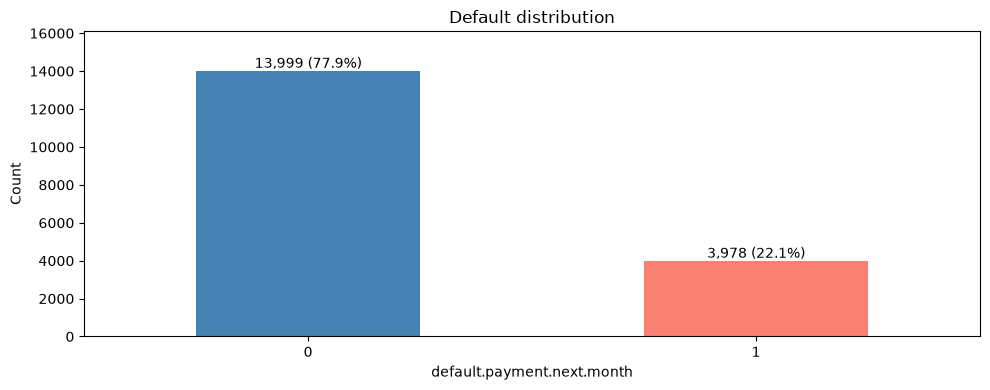

In [14]:
target_count = df_train[TARGET].value_counts().sort_index()
target_rate = target_count / len(df_train) * 100

fig, ax = plt.subplots()
target_count.plot.bar(ax=ax, rot=0, color=['steelblue', 'salmon'])
for i, count in enumerate(target_count):
    ax.text(i, count, f'{count:,} ({target_rate.iloc[i]:.1f}%)', ha='center', va='bottom')
ax.set(xlabel=TARGET, ylabel='Count', title='Default distribution')
ax.set_ylim(0, target_count.max() * 1.15)
plt.tight_layout()     
plt.show()

**Tuổi và hạn mức:**
+ So sánh phân phối theo nhãn default.
+ Dùng density để so sánh hai lớp có số lượng khác nhau.

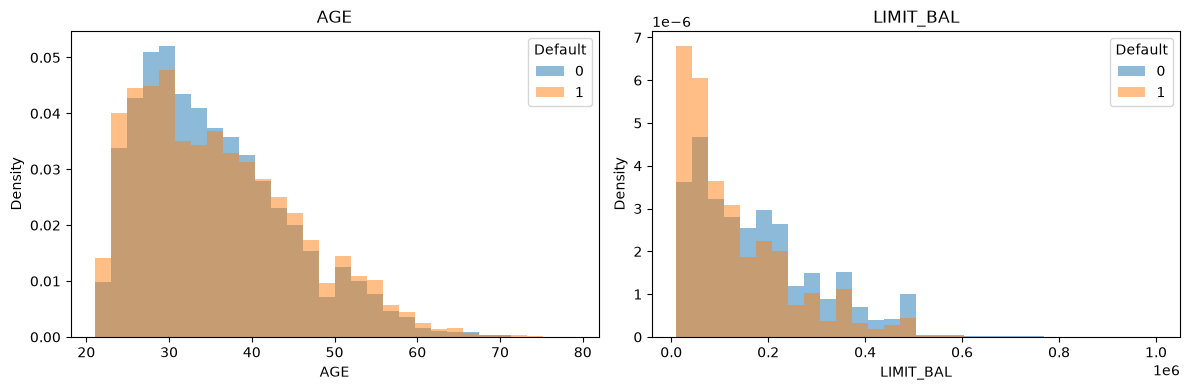

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ['AGE', 'LIMIT_BAL']):
    bins = np.histogram_bin_edges(df_train[col], bins=30)
    for label in [0, 1]:
        df_train.loc[df_train[TARGET] == label, col].plot.hist(
            bins=bins, density=True, alpha=0.5, label=str(label), ax=ax
        )
    ax.set(xlabel=col, ylabel='Density', title=col)
    ax.legend(title='Default')
plt.tight_layout()
plt.show()

**Biến phân loại:**
+ Sex: Đa phần khách hàng là nữ
+ Education: Số lượng khách hàng trong tập train chủ yếu là graduate school & university. Có một số lượng ít là đang high school
+ Marriage: Số lượng khách hàng đã cưới và chưa cưới không chênh lệch nhau quá nhiều

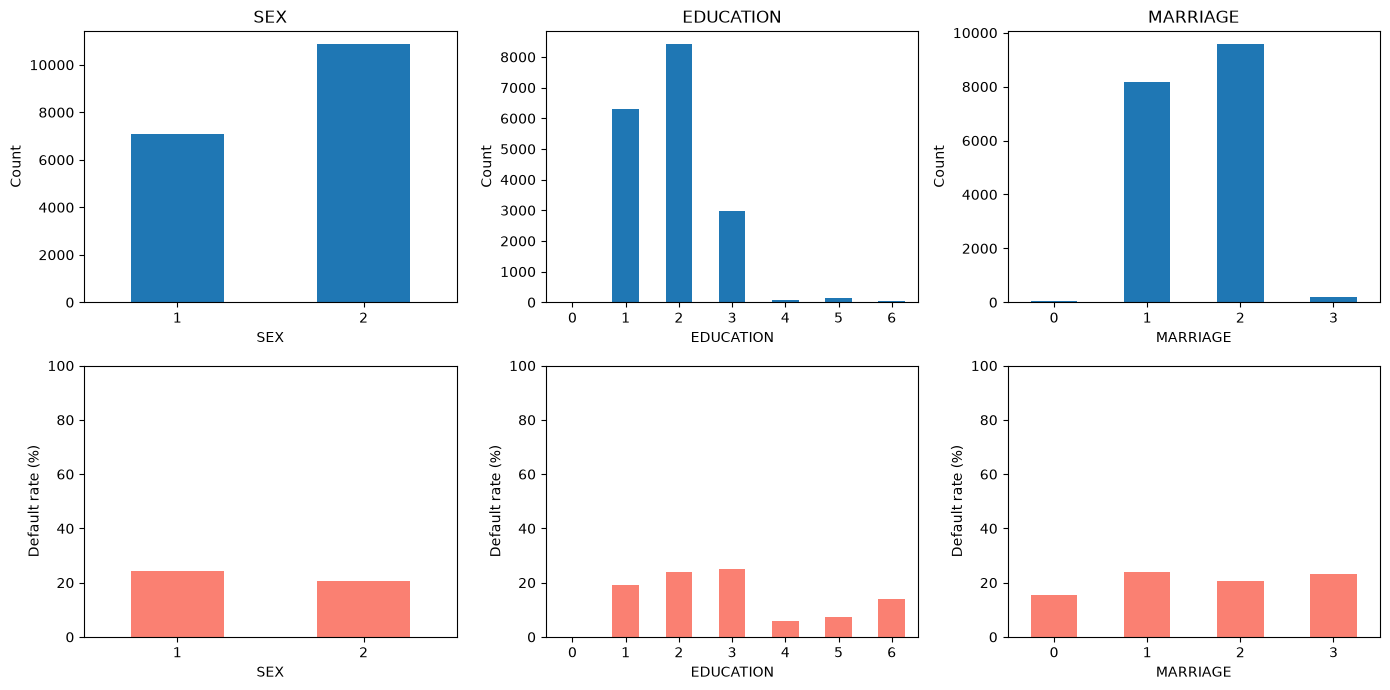

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for i, col in enumerate(['SEX', 'EDUCATION', 'MARRIAGE']):
    df_train[col].value_counts().sort_index().plot.bar(ax=axes[0, i], rot=0)
    (df_train.groupby(col)[TARGET].mean() * 100).plot.bar(ax=axes[1, i], rot=0, color='salmon')
    axes[0, i].set(xlabel=col, ylabel='Count', title=col)
    axes[1, i].set(xlabel=col, ylabel='Default rate (%)', ylim=(0, 100))
plt.tight_layout()
plt.show()

**Trạng thái thanh toán:**
+ Tỷ lệ default theo các mã PAY trong từng tháng.
+ n là số khách hàng của từng mã. Mã PAY > 0 thể hiện trạng thái trễ.
+ Thứ tự PAY_0 đến PAY_6 là gần nhất đến xa nhất.

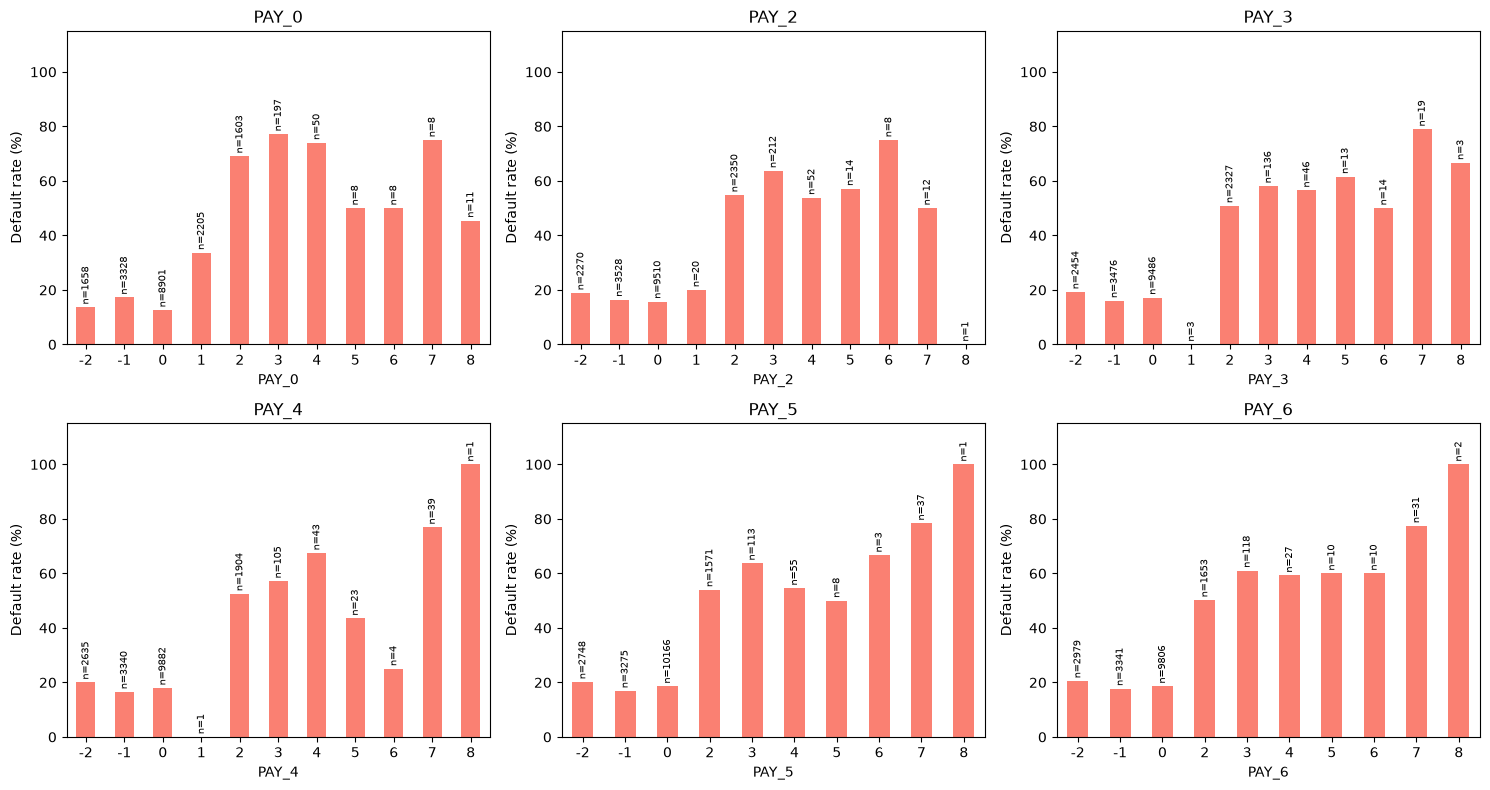

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.flat, PAY):
    pay_summary = df_train.groupby(col)[TARGET].agg(['mean', 'size'])
    (pay_summary['mean'] * 100).plot.bar(ax=ax, rot=0, color='salmon')
    for i, count in enumerate(pay_summary['size']):
        ax.text(i, pay_summary['mean'].iloc[i] * 100 + 1, f'n={count}',
                ha='center', va='bottom', fontsize=7, rotation=90)
    ax.set(xlabel=col, ylabel='Default rate (%)', title=col, ylim=(0, 115))
plt.tight_layout()
plt.show()

**Sao kê và thanh toán:**
+ So sánh median theo nhãn trong sáu tháng.
+ Hiển thị tháng 4 đến tháng 9 theo thứ tự thời gian.
+ Đây là giá trị tổng hợp của hai nhóm, không phải lịch sử của một khách hàng.

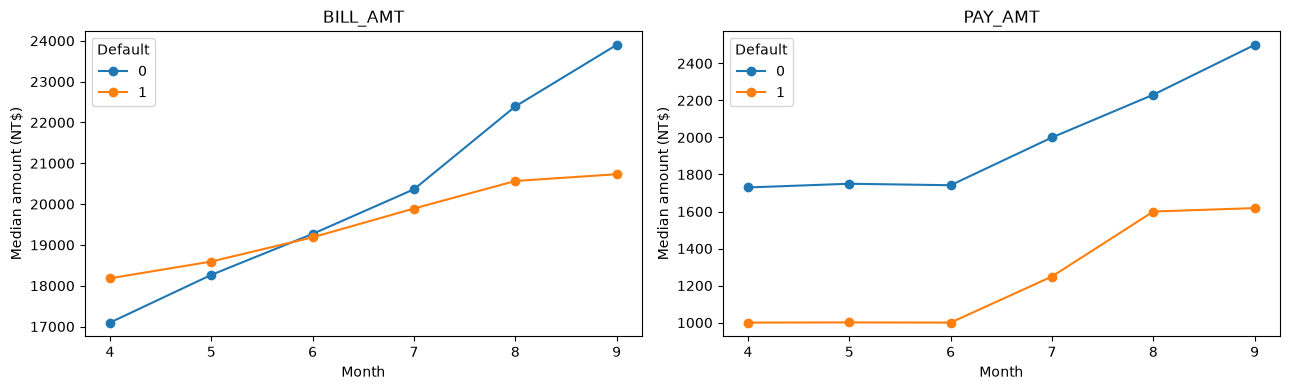

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, cols, title in zip(axes, [BILL, PAID], ['BILL_AMT', 'PAY_AMT']):
    for label in [0, 1]:
        median = df_train.loc[df_train[TARGET] == label, cols[::-1]].median()
        ax.plot([4, 5, 6, 7, 8, 9], median.to_numpy(), marker='o', label=str(label))
    ax.set(xlabel='Month', ylabel='Median amount (NT$)', title=title, xticks=[4, 5, 6, 7, 8, 9])
    ax.legend(title='Default')
plt.tight_layout()
plt.show()

**Tương quan:**
+ Spearman cho các biến số và nhãn default.
+ Tương quan thể hiện liên hệ thống kê, không kết luận quan hệ nhân quả.

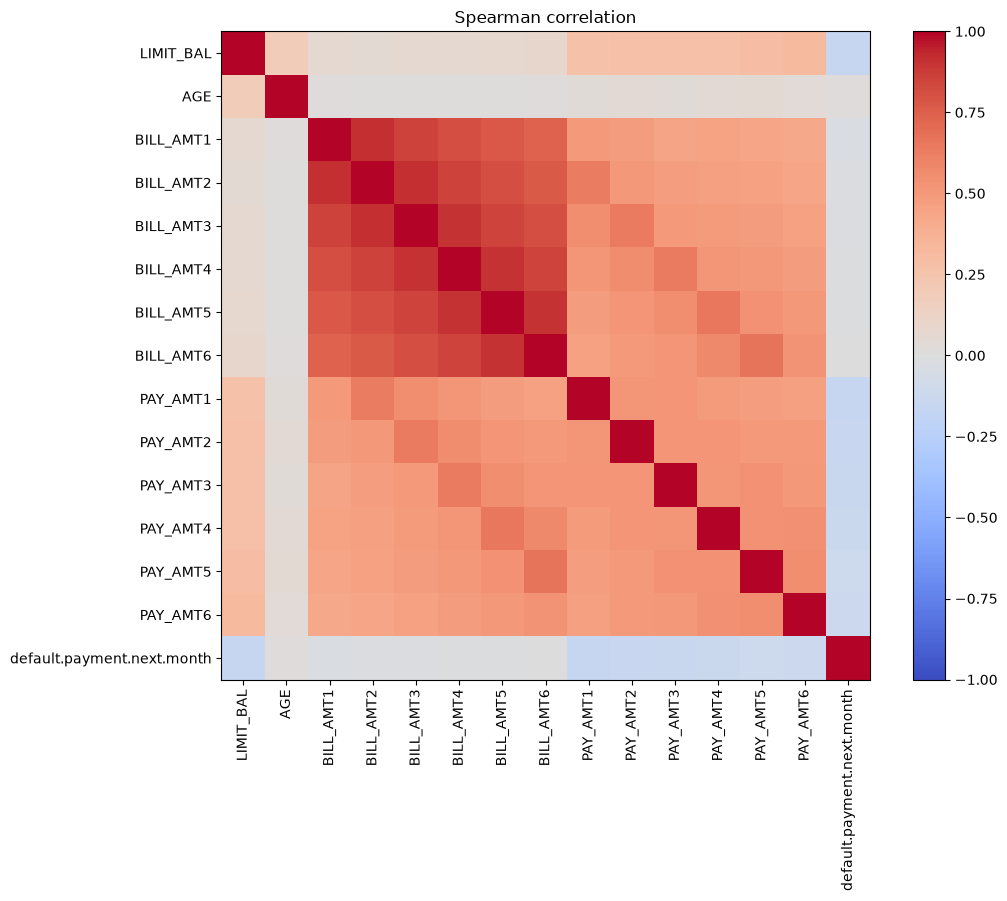

In [19]:
corr_cols = ['LIMIT_BAL', 'AGE'] + BILL + PAID + [TARGET]
corr = df_train[corr_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(11, 9))
image = ax.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=90)
ax.set_yticks(range(len(corr_cols)), corr_cols)
ax.set_title('Spearman correlation')
fig.colorbar(image, ax=ax)
plt.tight_layout()
plt.show()

# FEATURE ENGINEERING

Dựa trên khung phân tích khách hàng RFM (Recency–Frequency–Monetary), được điều chỉnh và mở rộng cho dữ liệu tín dụng (RFM Extended 12 chiều), ta xem mỗi dòng là một khách hàng với lịch sử thanh toán và dư nợ trong sáu tháng. Từ lịch sử này, các đặc trưng về thời điểm gần nhất, tần suất và giá trị tiền tệ được xây dựng để dự đoán khả năng khách hàng có hoặc không vỡ nợ thanh toán trong tháng tiếp theo.

In [20]:
RFM = ["r_months_since_delay", "f_total_delay_months", "m_amt_bill"]
RFM_EXT = [
    'r_months_since_delay', 'r_months_since_payment', 'r_delay_trend', 'r_recovery_age',
    'f_total_delay_months', 'f_recent_delay_months', 'f_overlimit_months', 'f_zero_payment_months',
    'm_amt_bill', 'm_latest_utilization', 'm_utilization_trend', 'm_payment_to_limit'
]

# rfm_splits
rfm_splits = {
    'train': X_train[RAW].copy(),
    'val': X_val[RAW].copy(),
    'test': X_test[RAW].copy()
}

**Recency:** Mức độ gần đây của hành vi thanh toán/trễ thanh toán
- `r_months_since_delay`: Khoảng cách đến tháng trễ gần nhất; 6 nếu không thấy trong cửa sổ.
- `r_months_since_payment`: Khoảng cách đến tháng có thanh toán dương gần nhất; 6 nếu không thấy.
- `r_delay_trend`: Mức trễ dương bình quân 3 tháng gần trừ 3 tháng xa.
- `r_recovery_age`: Số tháng từ lần chuyển trễ → không trễ gần nhất; 6 nếu không quan sát thấy. Mảng từ mới đến cũ, nên kỳ mới không trễ và kỳ cũ trễ là một lần phục hồi. Không hàm ý khách hàng vẫn đang không trễ ở hiện tại.

In [21]:
# Recency
for split in rfm_splits.values():
    delay = split[PAY].to_numpy() > 0
    split["r_months_since_delay"] = np.where(delay.any(axis=1), delay.argmax(axis=1), 6)

    has_pay = split[PAID].to_numpy() > 0
    split["r_months_since_payment"] = np.where(has_pay.any(axis=1), has_pay.argmax(axis=1), 6)

    severity = split[PAY].clip(lower=0).to_numpy()
    split["r_delay_trend"] = severity[:, :3].mean(axis=1) - severity[:, 3:].mean(axis=1)

    delay_trans = (~delay[:, :-1]) & delay[:, 1:]
    split["r_recovery_age"] = np.where(delay_trans.any(axis=1), delay_trans.argmax(axis=1), 6)

**Frequency**: Tần suất xuất hiện tình trạng trễ
- `f_total_delay_months`: Tổng số tháng trễ.
- `f_recent_delay_months`: Số tháng trễ trong 3 tháng gần nhất (PAY_0, 2, 3 > 0).
- `f_overlimit_months`: Số tháng có BILL_AMT vượt LIMIT_BAL.
- `f_zero_payment_months`: Số tháng có phát sinh sao kê nợ kỳ trước nhưng thanh toán = 0.

In [22]:
# Frequency
for split in rfm_splits.values():
    split["f_total_delay_months"] = (split[PAY] > 0).sum(axis=1)
    split["f_recent_delay_months"] = (split[['PAY_0', 'PAY_2', 'PAY_3']] > 0).sum(axis=1)

    limit = split['LIMIT_BAL'].to_numpy()
    bill_arr = split[BILL].clip(lower=0).to_numpy()
    paid_arr = split[PAID].to_numpy()

    split["f_overlimit_months"] = (split[BILL].to_numpy() > limit[:, None]).sum(axis=1)
    split["f_zero_payment_months"] = ((bill_arr[:, 1:] > 0) & (paid_arr[:, :5] <= 0)).sum(axis=1)

**Monetary:** Quy mô thanh toán so với số dư sao kê và hạn mức
- `m_amt_bill`: Tổng PAY_AMT1..5 / tổng phần dương BILL_AMT2..6. Đây là tỷ lệ tổng hợp, không phải tỷ lệ từng hóa đơn được trả hết; có thể lớn hơn 1. Mẫu số 0 → NaN, được impute từ train.
- `m_latest_utilization`: max(BILL_AMT1, 0) / LIMIT_BAL.
- `m_utilization_trend`: Phần dương sao kê / hạn mức, bình quân 3 tháng gần trừ 3 tháng xa.
- `m_payment_to_limit`: Thanh toán trung bình / LIMIT_BAL.

In [23]:
# Monetary
for split in rfm_splits.values():
    sum_bill = split[BILL[1:]].clip(lower=0).sum(axis=1)
    sum_pay = split[PAID[:5]].sum(axis=1)
    split["m_amt_bill"] = sum_pay / sum_bill.where(sum_bill > 0)

    limit = split['LIMIT_BAL'].to_numpy()
    bill_arr = split[BILL].clip(lower=0).to_numpy()

    split["m_latest_utilization"] = bill_arr[:, 0] / limit
    util = bill_arr / limit[:, None]
    split["m_utilization_trend"] = util[:, :3].mean(axis=1) - util[:, 3:].mean(axis=1)
    split["m_payment_to_limit"] = split[PAID].mean(axis=1) / split['LIMIT_BAL']

In [24]:
rfm_splits['train'].join(y_train)

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,r_months_since_delay,r_months_since_payment,r_delay_trend,r_recovery_age,f_total_delay_months,f_recent_delay_months,f_overlimit_months,f_zero_payment_months,m_amt_bill,m_latest_utilization,m_utilization_trend,m_payment_to_limit,default.payment.next.month
0,20000.0,2,2,1,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,0,1,1.333333,6,2,2,0,1,0.181746,0.195650,0.128400,0.005742,1
1,120000.0,2,2,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1,1,0.000000,0,2,1,0,2,0.208406,0.022350,-0.008053,0.006944,1
2,90000.0,2,2,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,6,0,0.000000,6,0,0,0,0,0.083105,0.324878,0.044433,0.020404,0
3,50000.0,2,2,1,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,6,0,0.000000,6,0,0,0,0,0.040077,0.939800,0.384627,0.027960,0
4,50000.0,1,2,1,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,6,0,0.000000,6,0,0,0,0,0.579516,0.172340,-0.060633,0.196830,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29992,10000.0,1,3,1,43,0,0,0,-2,-2,-2,8802.0,10400.0,0.0,0.0,0.0,0.0,2000.0,0.0,0.0,0.0,0.0,0.0,6,0,0.000000,6,0,0,1,0,0.192308,0.880200,0.640067,0.033333,0
29994,80000.0,1,2,2,34,2,2,2,2,2,2,72557.0,77708.0,79384.0,77519.0,82607.0,81158.0,7000.0,3500.0,0.0,7000.0,0.0,4000.0,0,0,0.000000,6,6,3,2,2,0.043928,0.906963,-0.048479,0.044792,1
29995,220000.0,1,3,1,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,6,0,0.000000,6,0,0,0,0,0.077461,0.858855,0.689253,0.032235,0
29997,30000.0,1,2,2,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,0,2,3.000000,6,3,3,0,2,0.421329,0.118833,-0.568200,0.173889,1


**Biểu đồ RFM:**
+ Hàng trên: số khách hàng theo nhóm R, F và M.
+ Hàng dưới: tỷ lệ default của từng nhóm.
+ R = 6 nghĩa là không quan sát thấy tháng trễ trong sáu tháng.
+ M được chia nhóm để vẽ, không thay đổi biến đầu vào của model. NaN là mẫu số bằng 0.

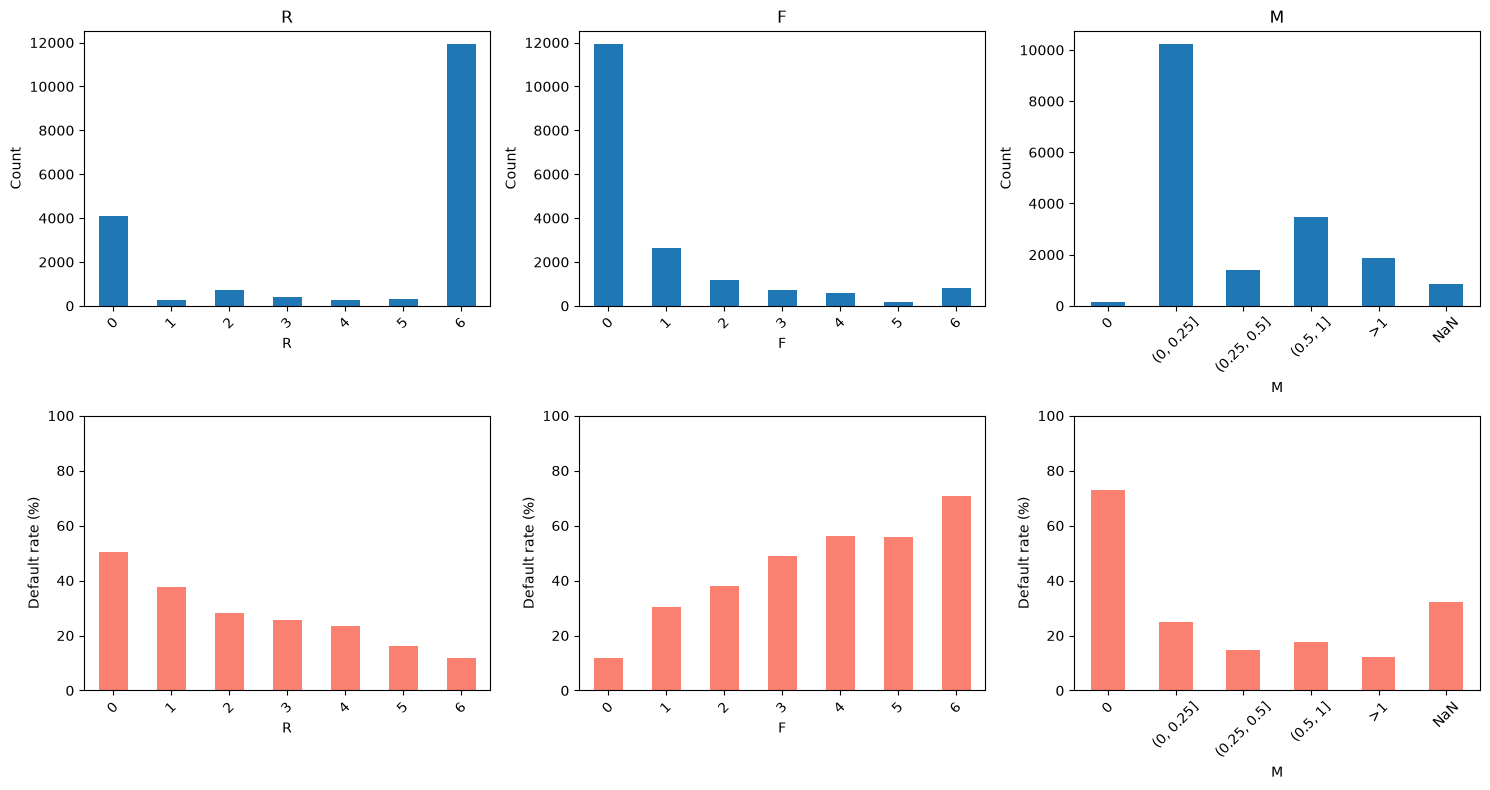

In [25]:
df_train_rfm = rfm_splits['train'].join(y_train)

m_group = pd.cut(
    df_train_rfm['m_amt_bill'], bins=[-np.inf, 0, 0.25, 0.5, 1, np.inf],
    labels=['0', '(0, 0.25]', '(0.25, 0.5]', '(0.5, 1]', '>1']
).cat.add_categories(['NaN']).fillna('NaN')

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for i, (name, group) in enumerate([
    ('R', df_train_rfm['r_months_since_delay']),
    ('F', df_train_rfm['f_total_delay_months']),
    ('M', m_group)
]):
    rfm_summary = df_train_rfm.groupby(group, observed=False)[TARGET].agg(['mean', 'size'])
    rfm_summary['size'].plot.bar(ax=axes[0, i], rot=45)
    (rfm_summary['mean'] * 100).plot.bar(ax=axes[1, i], rot=45, color='salmon')
    axes[0, i].set(xlabel=name, ylabel='Count', title=name)
    axes[1, i].set(xlabel=name, ylabel='Default rate (%)', ylim=(0, 100))
plt.tight_layout()
plt.show()

# MODEL

In [26]:
# Gán dữ liệu sau khi tạo biến
X_train = rfm_splits['train'].copy()
X_val = rfm_splits['val'].copy()
X_test = rfm_splits['test'].copy()

**Tiền xử lý và chọn mô hình bằng grouped CV:**
- So sánh Raw, Raw + RFM và Raw + RFM_Ext.
- Mỗi bộ đặc trưng có 2 cấu hình cho từng RF, XGBoost, LightGBM, CatBoost; thêm ensemble trung bình xác suất của 4 mô hình trong từng cấu hình. Tổng cộng 30 ứng viên, đánh giá cùng 3 fold theo nhóm bằng AP.
- Median impute biến số; mode impute và OneHotEncoder biến danh mục. Fit preprocessing riêng từng fold, chỉ dùng fold train.
- Chọn mean AP lớn nhất; nếu bằng nhau, thứ tự tên bộ đặc trưng/cấu hình/mô hình quyết định. Refit trên toàn bộ train.
- Cấu hình `compact` là đối chứng ít cây hơn; `research` tham khảo thực nghiệm trước trong `experiments/advanced_modeling_20261029/` và `experiments/rfm_advanced_20261029/`. LightGBM bật subsample_freq=1 để subsample có hiệu lực. Đây là lựa chọn trong tập ứng viên hữu hạn, không khẳng định tối ưu toàn cục.

In [27]:
# Thư viện mô hình & tiền xử lý
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.base import clone
from xgboost import XGBClassifier
import lightgbm as lgb
from catboost import CatBoostClassifier
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [28]:
# Danh sách đặc trưng
CAT = ['SEX', 'EDUCATION', 'MARRIAGE'] + PAY
features = {
    'Raw': RAW,
    'Raw + RFM': RAW + RFM,
    'Raw + RFM_Ext': RAW + RFM_EXT
}

In [29]:
# Fit 4 base models once per feature/config/fold; reuse their probabilities for avg4.
def make_preprocessor(cols):
    cat_cols = [c for c in cols if c in CAT]
    num_cols = [c for c in cols if c not in CAT]
    return ColumnTransformer([
        ('num', SimpleImputer(strategy='median'), num_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), cat_cols)
    ])


model_sets = {}
for config in ['compact', 'research']:
    small = config == 'compact'
    model_sets[config] = {
        'RF': RandomForestClassifier(
            n_estimators=100 if small else 300, max_depth=8 if small else 12,
            min_samples_leaf=10 if small else 5, random_state=SEED, n_jobs=2),
        'XGB': XGBClassifier(
            objective='binary:logistic', eval_metric='aucpr', tree_method='hist',
            n_estimators=200 if small else 500, learning_rate=0.03 if small else 0.02,
            max_depth=3 if small else 4, min_child_weight=5, subsample=0.8,
            colsample_bytree=0.8, random_state=SEED, n_jobs=2),
        'LGB': lgb.LGBMClassifier(
            n_estimators=300 if small else 600, learning_rate=0.03 if small else 0.015,
            num_leaves=15 if small else 31, max_depth=5, min_child_samples=15,
            subsample=0.71, subsample_freq=1, colsample_bytree=0.56,
            reg_alpha=5.92, reg_lambda=0.005, random_state=SEED, n_jobs=2, verbose=-1),
        'CB': CatBoostClassifier(
            iterations=200 if small else 300, learning_rate=0.03,
            depth=5 if small else 7, l2_leaf_reg=5.0, bagging_temperature=0.5,
            bootstrap_type='Bayesian', loss_function='Logloss', eval_metric='PRAUC',
            random_seed=SEED, verbose=False, thread_count=2, allow_writing_files=False)
    }

folds = list(cv.split(X_train, y_train, groups_train))
cv_rows = []
for feature_name, cols in features.items():
    for fold, (fit_idx, score_idx) in enumerate(folds, start=1):
        assert set(groups_train.iloc[fit_idx]).isdisjoint(groups_train.iloc[score_idx])
        fold_pre = make_preprocessor(cols)
        fit_X = fold_pre.fit_transform(X_train.iloc[fit_idx][cols])
        score_X = fold_pre.transform(X_train.iloc[score_idx][cols])
        for config, estimators in model_sets.items():
            probabilities = []
            for model_name, estimator in estimators.items():
                fitted = clone(estimator).fit(fit_X, y_train.iloc[fit_idx])
                proba = fitted.predict_proba(score_X)[:, 1]
                probabilities.append(proba)
                cv_rows.append(dict(features=feature_name, config=config, model=model_name,
                                    fold=fold, AP=average_precision_score(y_train.iloc[score_idx], proba)))
            cv_rows.append(dict(features=feature_name, config=config, model='avg4', fold=fold,
                                AP=average_precision_score(y_train.iloc[score_idx], np.mean(probabilities, axis=0))))
        print(f'Completed {feature_name}, fold {fold}/{FOLD}', flush=True)

cv_scores = pd.DataFrame(cv_rows)
cv_summary = (cv_scores.groupby(['features', 'config', 'model'], as_index=False)
              .agg(mean_AP=('AP', 'mean'), std_AP=('AP', 'std'), folds=('AP', 'size')))
assert len(cv_summary) == 30 and cv_summary['folds'].eq(FOLD).all()
cv_summary = cv_summary.sort_values(
    ['mean_AP', 'features', 'config', 'model'], ascending=[False, True, True, True]
).reset_index(drop=True)
selected = cv_summary.iloc[0]
cols = features[selected['features']]
estimators = model_sets[selected['config']]
estimator = (VotingClassifier(list(estimators.items()), voting='soft', n_jobs=1)
             if selected['model'] == 'avg4' else clone(estimators[selected['model']]))
selected_model = Pipeline([('preprocess', make_preprocessor(cols)), ('model', estimator)])
selected_model.fit(X_train[cols], y_train)
print('Selected:', selected[['features', 'config', 'model', 'mean_AP']].to_dict())
cv_summary

Completed Raw, fold 1/3


Completed Raw, fold 2/3


Completed Raw, fold 3/3


Completed Raw + RFM, fold 1/3


Completed Raw + RFM, fold 2/3


...

Completed Raw + RFM_Ext, fold 1/3


Completed Raw + RFM_Ext, fold 2/3


Completed Raw + RFM_Ext, fold 3/3


Selected: {'features': 'Raw + RFM_Ext', 'config': 'research', 'model': 'avg4', 'mean_AP': 0.5565596047451363}


,features,config,model,mean_AP,std_AP,folds
0,Raw + RFM_Ext,research,avg4,0.556560,0.015963,3
1,Raw + RFM_Ext,compact,avg4,0.556460,0.016640,3
2,Raw + RFM,research,CB,0.556139,0.017003,3
3,Raw + RFM,research,avg4,0.556085,0.016572,3
4,Raw + RFM_Ext,research,CB,0.555775,0.014490,3
5,Raw,research,CB,0.554907,0.018394,3
6,Raw + RFM_Ext,compact,CB,0.554004,0.017463,3
7,Raw + RFM_Ext,compact,XGB,0.553938,0.016101,3
8,Raw + RFM,compact,avg4,0.553794,0.019019,3
9,Raw + RFM,compact,CB,0.553643,0.020603,3


**Chọn ngưỡng trên tập Validation:**
- Dự đoán xác suất từ pipeline đã chọn bằng train CV.
- Chọn ngưỡng có F1 lớp default lớn nhất; nếu hòa, chọn ngưỡng lớn hơn.
- Không dùng điểm validation để chọn lại mô hình. F1 là mục tiêu hiện tại; nếu cần recall tối thiểu hoặc chi phí sai lầm khác nhau, phải xác định tiêu chí đó trước khi chọn ngưỡng.

In [30]:
# The selected pipeline is locked before validation threshold selection.
val_proba = selected_model.predict_proba(X_val[cols])[:, 1]

precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
val_f1 = np.divide(
    2 * precision[:-1] * recall[:-1],
    precision[:-1] + recall[:-1],
    out=np.zeros_like(thresholds),
    where=(precision[:-1] + recall[:-1]) > 0
)

threshold_result = pd.DataFrame({
    'threshold': thresholds,
    'precision': precision[:-1],
    'recall': recall[:-1],
    'F1': val_f1
}).sort_values(['F1', 'threshold'], ascending=[False, False]).reset_index(drop=True)

best_threshold = float(threshold_result.loc[0, 'threshold'])
threshold_result.head()

,threshold,precision,recall,F1
0,0.265020,0.531145,0.598039,0.562611
1,0.264929,0.530790,0.598039,0.562411
2,0.264339,0.530435,0.598039,0.562212
3,0.265041,0.530831,0.597285,0.562101
4,0.273382,0.537509,0.588989,0.562073


**Đánh giá nội bộ trên tập Test:**
- Dự đoán từ pipeline và bộ đặc trưng đã khóa, sau khi chọn ngưỡng trên validation.
- Báo cáo AP, ROC_AUC, Accuracy, Precision, Recall và F1 tại 0.5 và best_threshold. AP/AUC không phụ thuộc ngưỡng nên có cùng giá trị ở hai hàng.
- Các dòng trong dữ liệu này đã được xem trong nghiên cứu trước; đây không phải kiểm định trên dữ liệu mới độc lập. Không dùng bảng này để điều chỉnh lại mô hình hoặc ngưỡng.

In [31]:
# Report the locked model; test is not used to choose a candidate or threshold.
test_proba = selected_model.predict_proba(X_test[cols])[:, 1]

results = []
for threshold in [0.5, best_threshold]:
    test_pred = (test_proba >= threshold).astype(int)
    results.append({
        'threshold': threshold,
        'AP': average_precision_score(y_test, test_proba),
        'ROC_AUC': roc_auc_score(y_test, test_proba),
        'accuracy': accuracy_score(y_test, test_pred),
        'precision': precision_score(y_test, test_pred, zero_division=0),
        'recall': recall_score(y_test, test_pred, zero_division=0),
        'F1': f1_score(y_test, test_pred, zero_division=0)
    })

test_result = pd.DataFrame(results)
test_result

,threshold,AP,ROC_AUC,accuracy,precision,recall,F1
0,0.50000,0.566746,0.793325,0.821989,0.679612,0.369532,0.478749
1,0.26502,0.566746,0.793325,0.789790,0.522418,0.579940,0.549678


In [32]:
# Báo cáo phân loại chi tiết tại best_threshold
test_pred = (test_proba >= best_threshold).astype(int)
report = classification_report(y_test, test_pred, output_dict=True, zero_division=0)
pd.DataFrame(report).T

,precision,recall,f1-score,support
0,0.876824,0.84940,0.862894,4668.00000
1,0.522418,0.57994,0.549678,1326.00000
accuracy,0.789790,0.78979,0.789790,0.78979
macro avg,0.699621,0.71467,0.706286,5994.00000
weighted avg,0.798422,0.78979,0.793604,5994.00000


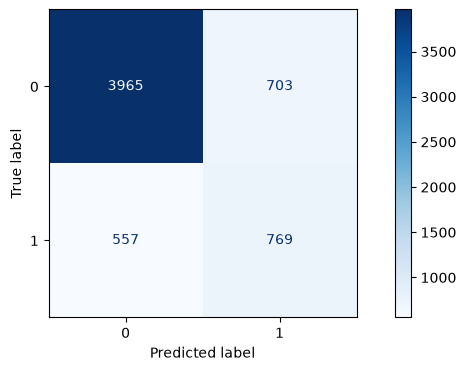

In [33]:
# Ma trận nhầm lẫn tại best_threshold
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=[0, 1]).plot(cmap='Blues')